In [1]:
!pip install rasterio -qq

In [29]:
from google.colab import drive
import ee
import geemap
import time
import rasterio
import numpy as np
import matplotlib.pyplot as plt
import geopandas as gpd
from shapely.geometry import Polygon, MultiPolygon

# mount google drive
drive.mount('/content/drive')

# autenticate for gee login
ee.Authenticate()

# project id
cloud_project = 'starting-with-gee-508912' # replace with your own project id
ee.Initialize(project=cloud_project)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


GEE_EO_CRYOSPHERE Übung 1

In [35]:
custom_aoi = Map.user_roi

# 2. Die Koordinaten extrahieren und anzeigen
# .getInfo() lädt die Daten von den Google-Servern in dein lokales Notebook
neue_koordinaten = custom_aoi.coordinates().getInfo()

print("Meine neuen Polygon-Koordinaten:")
print(neue_koordinaten)

Meine neuen Polygon-Koordinaten:
[[[81.768322, 30.198924], [81.785316, 30.200185], [81.782656, 30.20241], [81.780596, 30.2079], [81.780252, 30.215613], [81.780424, 30.223327], [81.778965, 30.228741], [81.776733, 30.231707], [81.774759, 30.231781], [81.771927, 30.225403], [81.77021, 30.216503], [81.770382, 30.211237], [81.770296, 30.206416], [81.766691, 30.202707], [81.765575, 30.199962], [81.768322, 30.198924]]]


In [75]:
import ee
import geemap

# 1. Dein neues, präzises handgezeichnetes Polygon
custom_coords = [[[81.768322, 30.198924], [81.785316, 30.200185], [81.782656, 30.20241],
                  [81.780596, 30.2079], [81.780252, 30.215613], [81.780424, 30.223327],
                  [81.778965, 30.228741], [81.776733, 30.231707], [81.774759, 30.231781],
                  [81.771927, 30.225403], [81.77021, 30.216503], [81.770382, 30.211237],
                  [81.770296, 30.206416], [81.766691, 30.202707], [81.765575, 30.199962],
                  [81.768322, 30.198924]]]

custom_aoi = ee.Geometry.Polygon(custom_coords)

# 2. Funktion, die Bild laden, NDSI berechnen und maskieren in einem Schritt erledigt
def get_glacier_area_for_year(year, aoi):
    # 1. Zeitfenster deutlich vergrößern (Nach dem Monsun sind die Bilder besser)
    start_date = f'{year}-08-01'
    end_date = f'{year}-09-30'

    # 2. Wolkentoleranz auf 40% erhöhen (der .median() glättet die Reste)
    collection = (ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
                  .filterBounds(aoi)
                  .filterDate(start_date, end_date)
                  .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 40)))

    # 3. Den "No band B3"-Absturz verhindern:
    # Zählen, ob nach dem Filtern überhaupt Bilder übrig sind
    count = collection.size().getInfo()
    if count == 0:
        return None # Gibt "None" zurück, statt abzustürzen

    image = collection.median()
    ndsi = image.normalizedDifference(['B3', 'B11']).rename('NDSI')

    # Binäre Maske erstellen
    mask = ndsi.gt(0.4).selfMask().clip(aoi)

    # Fläche berechnen
    area_image = mask.multiply(ee.Image.pixelArea())
    stats = area_image.reduceRegion(
        reducer=ee.Reducer.sum(),
        geometry=aoi,
        scale=20,
        maxPixels=1e9
    )

    # Resultat abrufen
    area_m2 = stats.get('NDSI').getInfo()

    # Falls das Bild durch Maskierung komplett leer ist (z.B. extrem schattig)
    if area_m2 is None:
        return None

    return area_m2 / 1e6

# 3. Karte vorbereiten
Map = geemap.Map(basemap='HYBRID')
Map.centerObject(custom_aoi, 14)

# 4. Jahre definieren und eine Farbpalette festlegen (9 Jahre = 9 Farben)
jahre = list(range(2015, 2024))
# Wir nutzen einen Farbverlauf von Rot (2015) über Gelb und Grün bis Blau/Violett (2023)
farben = ['#d7191c', '#f57a5a', '#fdbf6f', '#ffffbf', '#c7e9b4', '#7fcdbb', '#41b6c4', '#2c7fb8', '#253494']

# 5. In einer Schleife alle Jahre verarbeiten und zur Karte hinzufügen
for i, year in enumerate(jahre):
    # Maske für das jeweilige Jahr berechnen
    mask_year = get_glacier_mask(year, custom_aoi)

    # Maske als eigenen Layer hinzufügen
    Map.addLayer(mask_year, {'palette': [farben[i]]}, f'Gletscher {year}')

# GLIMS-Umrisse einblenden (orange)
Map.addLayer(ee.Image().paint(glims, 1, 2), {'palette': ['orange']}, 'GLIMS Referenzumrisse')

# Zum Schluss noch den Umriss deiner Custom AOI in Rot darüberlegen
Map.addLayer(ee.Image().paint(custom_aoi, 1, 2), {'palette': ['red']}, 'Meine AOI')

Map

Map(center=[30.212620057076144, 81.77534281078347], controls=(WidgetControl(options=['position', 'transparent_…

Berechne saisonale Gletscherflächen über die Jahre. Bitte warten...

--- Verarbeite Zeitraum: Januar - März ---
Jahr 2015: Keine Daten verfügbar.
Jahr 2016: 2.993 km²
Jahr 2017: 3.225 km²
Jahr 2018: 2.564 km²
Jahr 2019: 3.415 km²
Jahr 2020: 3.459 km²
Jahr 2021: 2.811 km²
Jahr 2022: 3.456 km²
Jahr 2023: 3.378 km²

--- Verarbeite Zeitraum: April - Juni ---
Jahr 2015: Keine Daten verfügbar.
Jahr 2016: 2.617 km²
Jahr 2017: 2.369 km²
Jahr 2018: 2.679 km²
Jahr 2019: 3.264 km²
Jahr 2020: 3.004 km²
Jahr 2021: 3.401 km²
Jahr 2022: 2.874 km²
Jahr 2023: 3.002 km²

--- Verarbeite Zeitraum: Juli - September ---
Jahr 2015: Keine Daten verfügbar.
Jahr 2016: 1.285 km²
Jahr 2017: 1.513 km²
Jahr 2018: 1.436 km²
Jahr 2019: 1.144 km²
Jahr 2020: 1.400 km²
Jahr 2021: 1.820 km²
Jahr 2022: 0.454 km²
Jahr 2023: 1.442 km²

--- Verarbeite Zeitraum: Oktober - Dezember ---
Jahr 2015: 1.600 km²
Jahr 2016: 1.569 km²
Jahr 2017: 1.942 km²
Jahr 2018: 2.490 km²
Jahr 2019: 2.280 km²
Jahr 2020: 2.220 km²
Jahr 2021: 3.411 

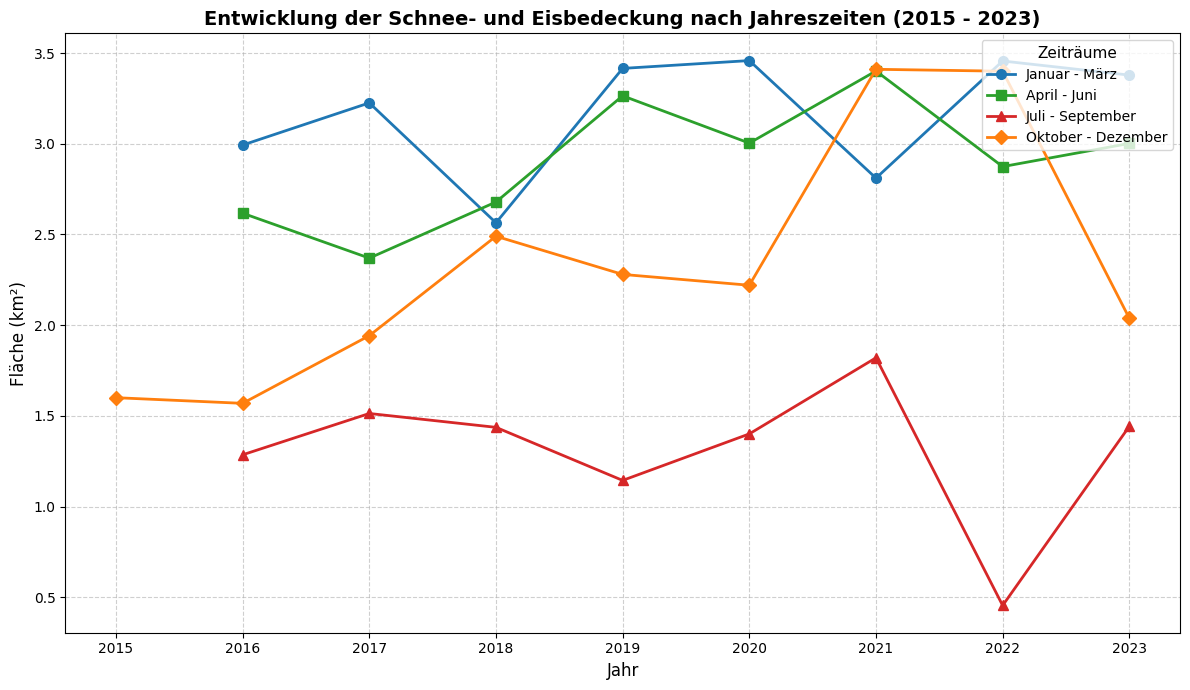

In [68]:
import matplotlib.pyplot as plt

# 2. Die vier gewünschten Jahreszeiten definieren (Start- und Enddatum als Suffix)
saisons = {
    'Januar - März': ('01-01', '03-31'), # 28. Feb verhindert Schaltjahr-Errors
    'April - Juni': ('04-01', '06-30'),
    'Juli - September': ('07-01', '09-30'),
    'Oktober - Dezember': ('10-01', '12-30')
}

# 3. Funktion zur Flächenberechnung mit flexiblen Datums-Parametern
def get_glacier_area_for_period(year, start_suffix, end_suffix, aoi):
    start_date = f'{year}-{start_suffix}'
    end_date = f'{year}-{end_suffix}'

    collection = (ee.ImageCollection('COPERNICUS/S2_HARMONIZED')
                  .filterBounds(aoi)
                  .filterDate(start_date, end_date)
                  .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 50)))

    count = collection.size().getInfo()
    if count == 0:
        return None

    image = collection.median()
    ndsi = image.normalizedDifference(['B3', 'B11']).rename('NDSI')

    mask = ndsi.gt(0.4).selfMask().clip(aoi)
    area_image = mask.multiply(ee.Image.pixelArea())

    stats = area_image.reduceRegion(
        reducer=ee.Reducer.sum(),
        geometry=aoi,
        scale=20,
        maxPixels=1e9
    )

    area_m2 = stats.get('NDSI').getInfo()
    if area_m2 is None:
        return None

    return area_m2 / 1e6

# 4. Daten für alle Jahre und alle vier Saison-Linien sammeln
jahre = list(range(2015, 2024))
# Verschachteltes Dictionary, um Jahre und Flächen pro Saison getrennt zu speichern
saison_daten = {name: {'jahre': [], 'flaechen': []} for name in saisons}

print("Berechne saisonale Gletscherflächen über die Jahre. Bitte warten...")
for name, (start, end) in saisons.items():
    print(f"\n--- Verarbeite Zeitraum: {name} ---")
    for year in jahre:
        area = get_glacier_area_for_period(year, start, end, custom_aoi)
        if area is not None:
            saison_daten[name]['jahre'].append(year)
            saison_daten[name]['flaechen'].append(area)
            print(f"Jahr {year}: {area:.3f} km²")
        else:
            print(f"Jahr {year}: Keine Daten verfügbar.")

# 5. Multiline-Plot mit Matplotlib erstellen
plt.figure(figsize=(12, 7))

# Farben und Marker für die vier verschiedenen Linien
farben = ['#1f77b4', '#2ca02c', '#d62728', '#ff7f0e']
marker_styles = ['o', 's', '^', 'D']

# Jede Jahreszeit als eigene Linie in den Plot einfügen
for (name, daten), farbe, marker in zip(saison_daten.items(), farben, marker_styles):
    if daten['flaechen']: # Nur plotten, wenn auch Daten vorhanden sind
        plt.plot(daten['jahre'], daten['flaechen'], marker=marker, linestyle='-',
                 color=farbe, linewidth=2, markersize=7, label=name)

# Achsen und Titel
plt.title('Entwicklung der Schnee- und Eisbedeckung nach Jahreszeiten (2015 - 2023)', fontsize=14, fontweight='bold')
plt.xlabel('Jahr', fontsize=12)
plt.ylabel('Fläche (km²)', fontsize=12)

# X-Achse so einstellen, dass nur ganze Jahreszahlen angezeigt werden
plt.xticks(jahre)

# Raster und Legende hinzufügen
plt.grid(axis='both', linestyle='--', alpha=0.6)
plt.legend(title='Zeiträume', fontsize=10, title_fontsize=11, loc='upper right')

plt.tight_layout()
plt.show()

Berechne monatliche Eis- und Schneebedeckung für das Jahr 2021...
Jan: 2.428 km²
Feb: 2.810 km²
Mär: 3.041 km²
Apr: 3.303 km²
Mai: 2.767 km²
Jun: 2.841 km²
Jul: 2.350 km²
Aug: 0.682 km²
Sep: 1.189 km²
Okt: 2.771 km²
Nov: 3.411 km²
Dez: 3.411 km²


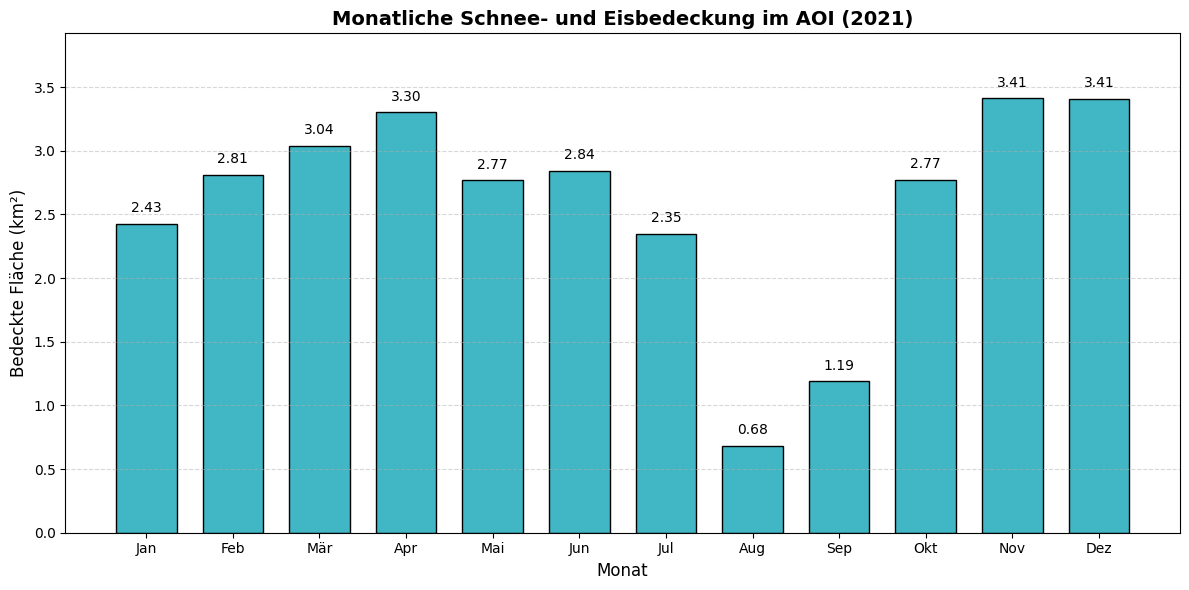

In [58]:
import ee
import matplotlib.pyplot as plt
import calendar

# 1. Deine Custom AOI
custom_coords = [[[81.768322, 30.198924], [81.785316, 30.200185], [81.782656, 30.20241],
                  [81.780596, 30.2079], [81.780252, 30.215613], [81.780424, 30.223327],
                  [81.778965, 30.228741], [81.776733, 30.231707], [81.774759, 30.231781],
                  [81.771927, 30.225403], [81.77021, 30.216503], [81.770382, 30.211237],
                  [81.770296, 30.206416], [81.766691, 30.202707], [81.765575, 30.199962],
                  [81.768322, 30.198924]]]
custom_aoi = ee.Geometry.Polygon(custom_coords)

# 2. Funktion zur Berechnung pro Monat
def get_monthly_area(year, month, aoi):
    # Den letzten Tag des Monats automatisch ermitteln
    last_day = calendar.monthrange(year, month)[1]

    start_date = f'{year}-{month:02d}-01'
    end_date = f'{year}-{month:02d}-{last_day}'

    collection = (ee.ImageCollection('COPERNICUS/S2_HARMONIZED')
                  .filterBounds(aoi)
                  .filterDate(start_date, end_date)
                  .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 60)))

    count = collection.size().getInfo()
    if count == 0:
        return None

    image = collection.median()
    ndsi = image.normalizedDifference(['B3', 'B11']).rename('NDSI')

    mask = ndsi.gt(0.4).selfMask().clip(aoi)
    area_image = mask.multiply(ee.Image.pixelArea())

    stats = area_image.reduceRegion(
        reducer=ee.Reducer.sum(),
        geometry=aoi,
        scale=20,
        maxPixels=1e9
    )

    area_m2 = stats.get('NDSI').getInfo()

    if area_m2 is None:
        return None

    return area_m2 / 1e6

# 3. Daten für alle 12 Monate berechnen
year = 2021
monate = ['Jan', 'Feb', 'Mär', 'Apr', 'Mai', 'Jun', 'Jul', 'Aug', 'Sep', 'Okt', 'Nov', 'Dez']
monats_flaechen = []

print(f"Berechne monatliche Eis- und Schneebedeckung für das Jahr {year}...")
for month in range(1, 13):
    area = get_monthly_area(year, month, custom_aoi)
    if area is not None:
        monats_flaechen.append(area)
        print(f"{monate[month-1]}: {area:.3f} km²")
    else:
        monats_flaechen.append(0)
        print(f"{monate[month-1]}: Keine Daten verfügbar.")

# 4. Balkendiagramm für die 12 Monate erstellen
plt.figure(figsize=(12, 6))

# Ein schöner Blauton für Schnee und Eis
bars = plt.bar(monate, monats_flaechen, color='#41b6c4', edgecolor='black', width=0.7)

plt.title(f'Monatliche Schnee- und Eisbedeckung im AOI ({year})', fontsize=14, fontweight='bold')
plt.ylabel('Bedeckte Fläche (km²)', fontsize=12)
plt.xlabel('Monat', fontsize=12)

# Die Werte über die Balken schreiben
for bar in bars:
    yval = bar.get_height()
    if yval > 0:
        plt.text(bar.get_x() + bar.get_width()/2, yval + (max(monats_flaechen)*0.02),
                 f'{yval:.2f}', ha='center', va='bottom', fontsize=10)
    else:
        # Falls in den Sommermonaten wegen Monsun-Wolken keine Daten vorliegen
        plt.text(bar.get_x() + bar.get_width()/2, 0.1,
                 'Keine\nDaten', ha='center', va='bottom', color='red', fontsize=9)

# Y-Achse dynamisch skalieren, wenn Daten vorhanden sind
if max(monats_flaechen) > 0:
    plt.ylim(0, max(monats_flaechen) * 1.15)

plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()